In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_selected = pd.read_csv('/content/NIFTY-29FEB24-28FEB24.csv')


display(df_selected.head())
display(df_selected.info())

,datetime,strike_price,right,open,high,low,close,open_interest,volume
0,09:15,19000,CE,3188.4,3203.5,3188.4,3203.5,382250,350
1,09:16,19000,CE,3203.5,3203.5,3203.5,3203.5,382050,450
2,09:17,19000,CE,3203.5,3203.5,3203.5,3203.5,382050,0
3,09:18,19000,CE,3203.5,3209.3,3203.5,3209.3,382050,50
4,09:19,19000,CE,3209.9,3209.9,3209.9,3209.9,382050,50


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65836 entries, 0 to 65835
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       65836 non-null  object 
 1   strike_price   65836 non-null  int64  
 2   right          65836 non-null  object 
 3   open           65836 non-null  float64
 4   high           65836 non-null  float64
 5   low            65836 non-null  float64
 6   close          65836 non-null  float64
 7   open_interest  65836 non-null  int64  
 8   volume         65836 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 4.5+ MB


None

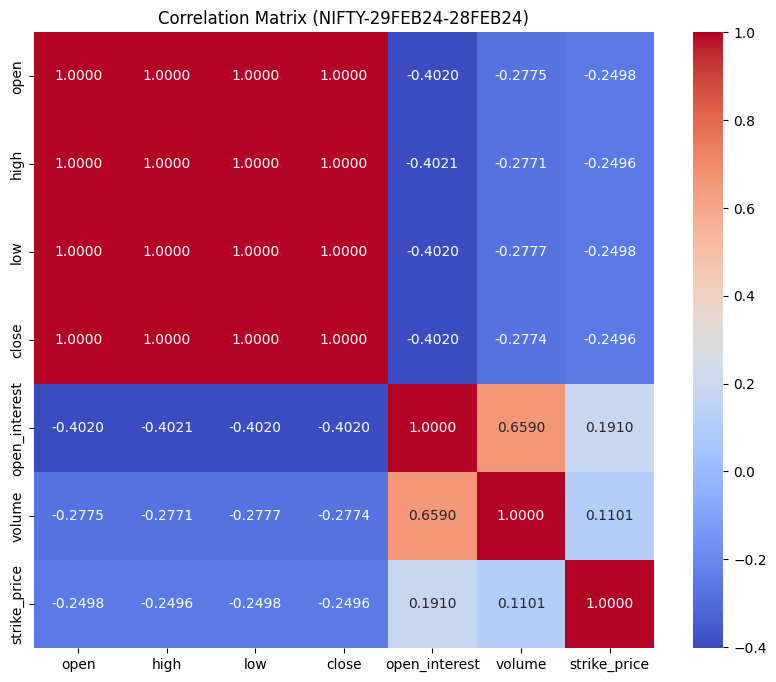

In [6]:

numerical_cols = ['open', 'high', 'low', 'close', 'open_interest', 'volume', 'strike_price']
corr_matrix_selected = df_selected[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_selected, annot=True, cmap='coolwarm', fmt='.4f')
plt.title('Correlation Matrix (NIFTY-29FEB24-28FEB24)')
plt.show()

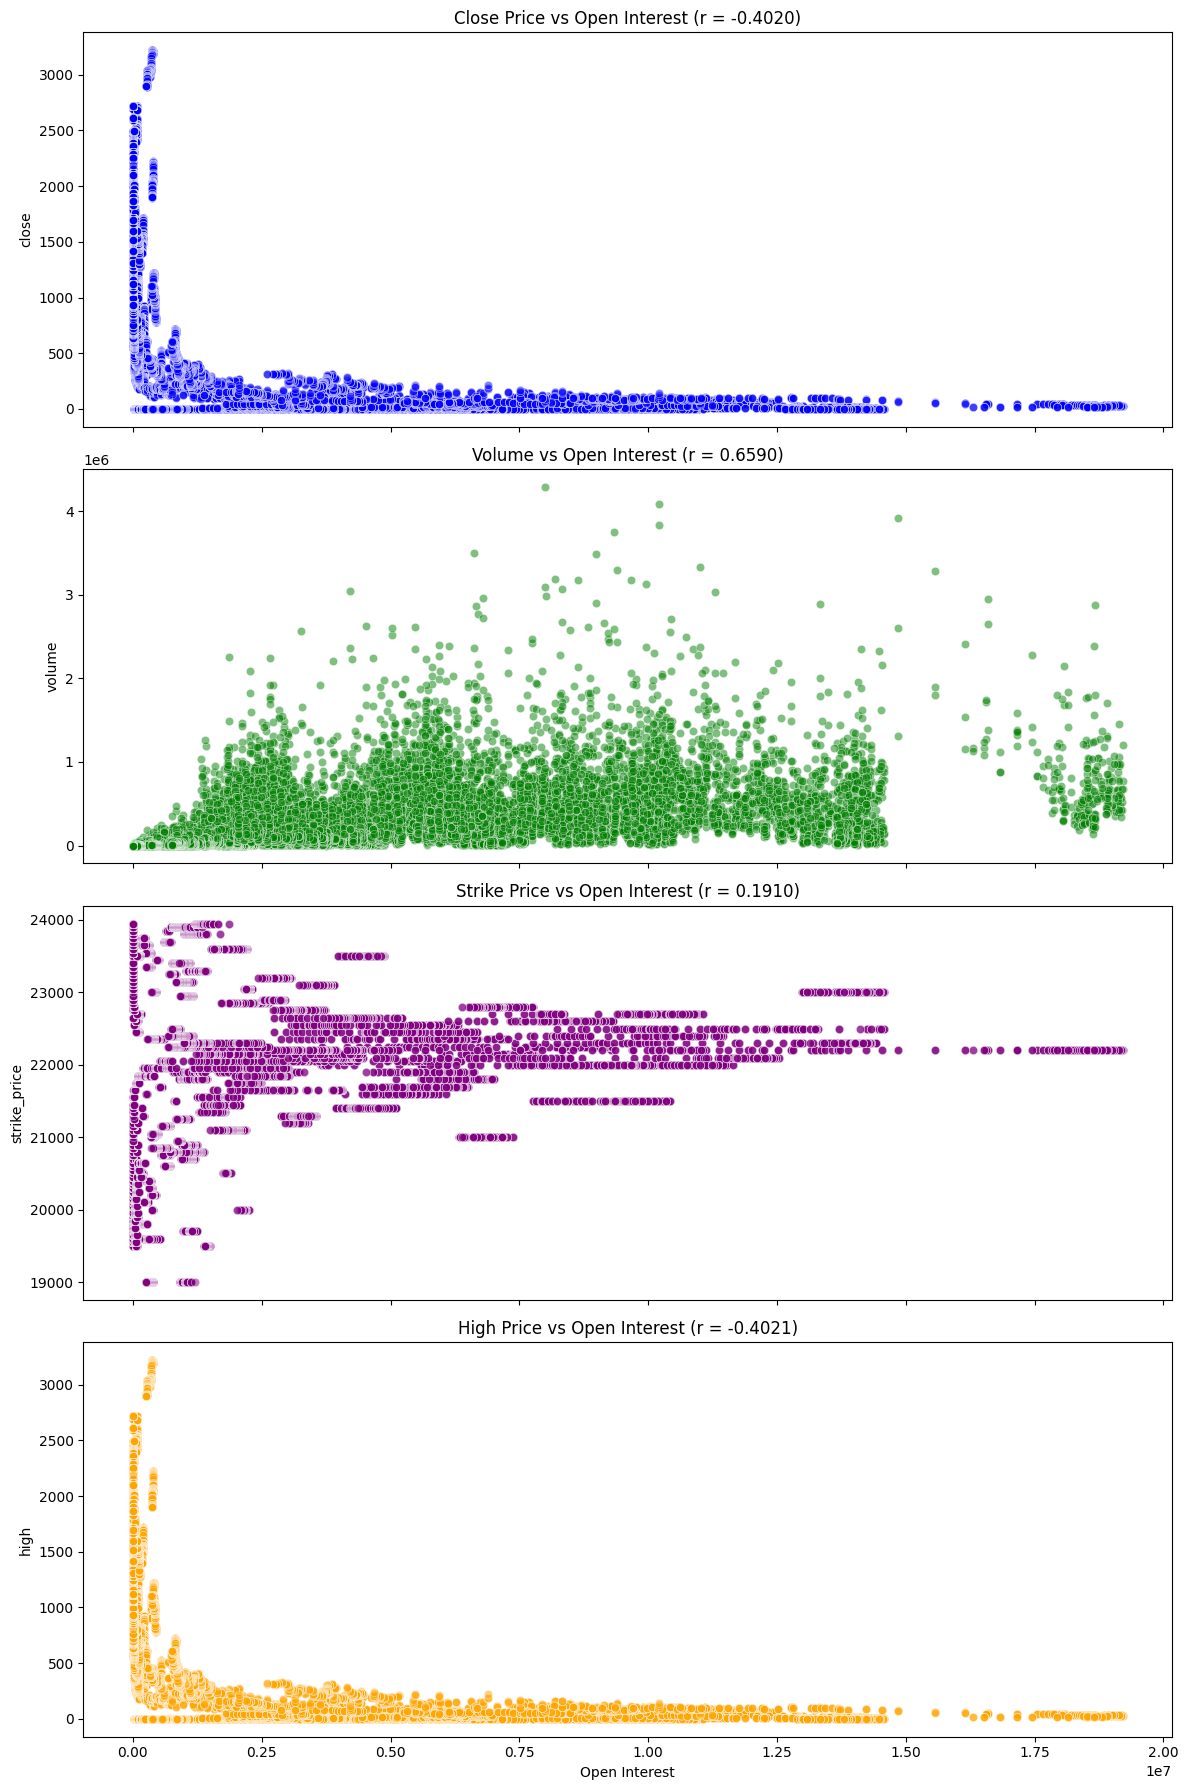

In [7]:

fig, axes = plt.subplots(4, 1, figsize=(12, 18), sharex=True)

targets = [
    ('close', 'blue', 'Close Price vs Open Interest'),
    ('volume', 'green', 'Volume vs Open Interest'),
    ('strike_price', 'purple', 'Strike Price vs Open Interest'),
    ('high', 'orange', 'High Price vs Open Interest')
]

for idx, (col, color, title) in enumerate(targets):
    corr_val = df_selected['open_interest'].corr(df_selected[col])
    sns.scatterplot(ax=axes[idx], data=df_selected, x='open_interest', y=col, alpha=0.5, color=color)
    axes[idx].set_title(f'{title} (r = {corr_val:.4f})')
    axes[idx].set_xlabel('Open Interest')
    axes[idx].set_ylabel(col)

plt.tight_layout()
plt.show()